# Quantum Metal A.3 — four qubits with multiplexed readout (Quantcore PDK rebuild)

**What the chip is.** The frequency-multiplexed readout example from the Qiskit Metal tutorial
`docs/tut/full-design-examples/A.3-Four-qubit-multiplexed-readout.ipynb` (© IBM / Qiskit Metal contributors,
Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec `docs/designs/metal/A3_four_qubit_mux.md`):
four uncoupled `TransmonPocket`s (pad width 425 µm, pocket height 650 µm, one readout pad at the upper right) in a
row at x = −4.5, −1.5, 1.5, 4.5 mm; each has a λ/4 `RouteMeander` readout (6.8, 7.0, 7.2, 7.4 mm) from a
`CoupledLineTee` on one feedline between two `LaunchpadWirebond`s, so the four readouts sit at four distinct tones
on one line. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options, but the chip, the
stack, the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 16 × 9 mm centred on (0, 0) | the same 16 × 9 mm box (it does not fit the 7.5 mm die), shifted by (+8, +4.5) mm, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | `LaunchpadWirebond` at x = ±7.5 mm (outer edge 240 µm in) | the same pads, moved to **100 µm** (`frame.pad_edge`) from the west / east edges (PDK pad rule) |
| junctions | Metal junction line, `hfss_inductance` 10 nH | Quantcore Nb/AlOx/Nb trilayer junctions, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) on all four qubits |
| cheese | none (the tutorial never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| routes | `RoutePathfinder` feedline segments, `RouteMeander` readouts | qcc `cpw` routes on the same pins; qcc meanders of the same lengths (6800 … 7400 µm; turn radius 90 µm = Metal's fillet) |
| placement | as drawn | content centred in the die |

**Kept exactly:** every component with the tutorial's options (tees: `coupling_length` 350 µm, `down_length`
300 µm, `fillet` 90 µm, `open_termination=False`), their relative positions, the five feedline segments, every
route's end pins and the readout total lengths, the four sim groups.

**Simplified:** the qcc router places each readout meander itself (Metal: 100 µm lead straights): same end points
and lengths, different meander footprints.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the two bond pads, the readout line (four tees on one feedline), the four
qubits, their four readout resonators, and then the whole chip. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `a3_four_qubit_mux.v1.ipynb`; both save the same
`a3_four_qubit_mux.json`.

## Setup

The imports, the output folder and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 16 × 9 mm box gets the QCT frame; the two launchpads go 100 µm from the west and east edges; all four qubits get the PDK nominal trilayer junction; the free ground gets the PDK cheese band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). In the Designer a route always joins two ports, so the feedline (input pad → four tees → output pad) is
drawn as soon as the pads and the tees exist (segment 3), the readouts once the qubits are there (segment 5).

| segment | what is placed here |
|---|---|
| 1 | the 16 × 9 mm die with the QCT frame |
| 2 | the input and output launchpads, 100 µm from the west / east edges |
| 3 | the readout line: four coupled-line tees on one feedline (five `cpw` sections) |
| 4 | the four qubits with their trilayer junctions |
| 5 | the four λ/4 readout resonators (6.8, 7.0, 7.2, 7.4 mm) |
| 6–7 | nothing: the qubits are uncoupled, and the tutorial has no control lines |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (it is optional: no free edge, no ID). Metal centres its chip on
(0, 0); our box starts at (0, 0), so every Metal position is shifted by `(X0, Y0)` = half the chip.

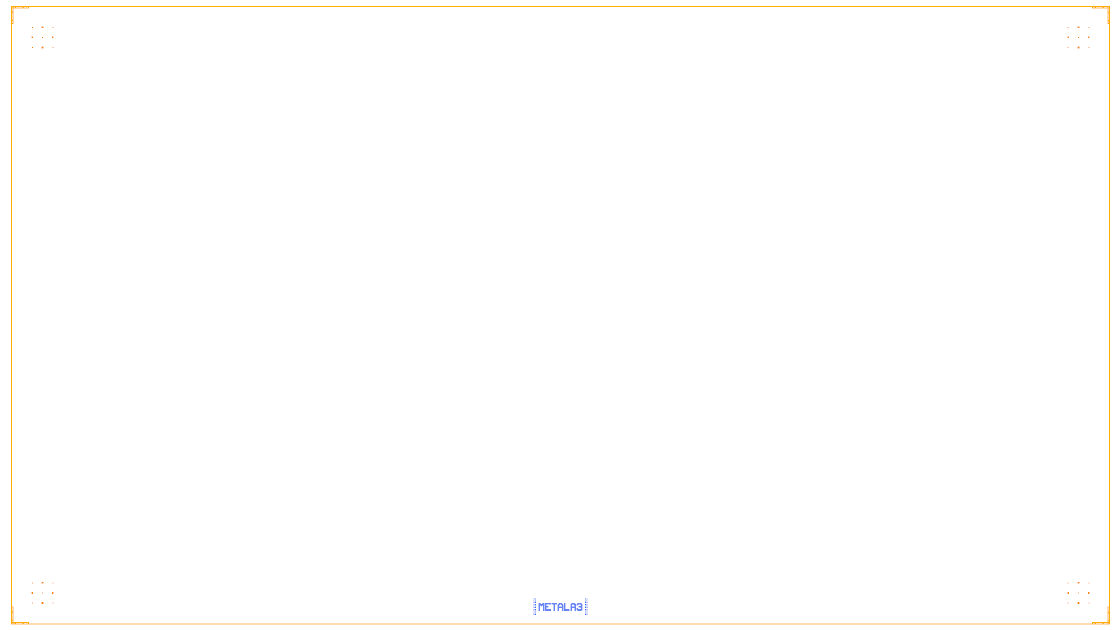

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a3_four_qubit_mux_s1_die.png')

In [5]:
d = Designer("a3_four_qubit_mux", box=(0, 0, 16000, 9000), chip={"name_chip": "MetalA3"}, live=LIVE)
X0, Y0 = 8000, 4500                              # Metal's 16 × 9 mm chip is centred on (0, 0)
layout_step(d, OUT / "a3_four_qubit_mux_s1_die.png", size=(1120, 630), width=450)

## Design 2 · Bond pads: the PDK pad rule

The tutorial puts its input and output `LaunchpadWirebond`s at x = ±7.5 mm on the feedline height, 240 µm in from
the die edge. In the Quantcore PDK the outer edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm
from the die edge**, whatever the source did: `edge="w"` / `"e"` slides the pad perpendicular to that edge until it
is there; its position along the edge (the feedline height) is kept. The table measures it on the built layout; the picture zooms on the input pad `LPin`.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LPin | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LPout | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

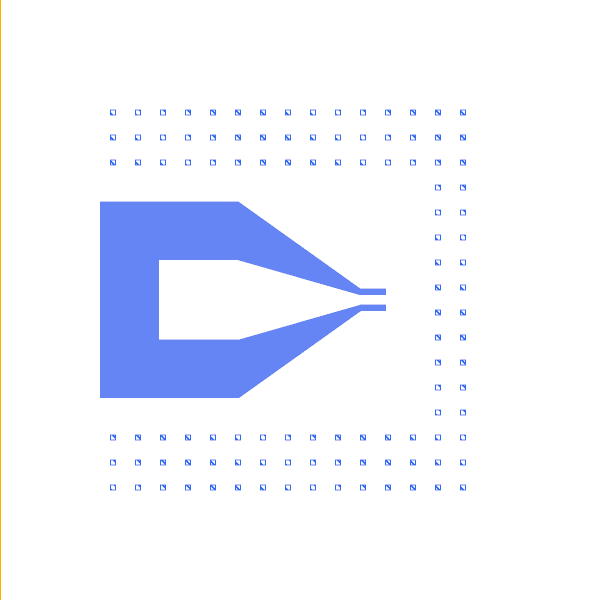

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `LPin`, `LPout`.

WindowsPath('examples/designs/metal/a3_four_qubit_mux_s2_pads.png')

In [6]:
with d.batch():
    d.add("LPin", "metal:LaunchpadWirebond", at=(X0 - 7500, Y0 + 1800), rot=0, edge="w")
    d.add("LPout", "metal:LaunchpadWirebond", at=(X0 + 7500, Y0 + 1800), rot=180, edge="e")
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "LPin.tie")
layout_step(d, OUT / "a3_four_qubit_mux_s2_pads.png", box=(0, py - 300, 600, py + 300), size=(600, 600), width=300)

## Design 3 · Readout: four tees on one feedline

The readout line needs no qubit, so it comes first. Four `metal:CoupledLineTee`s on the feedline, above their qubits, each with a 350 µm coupled arm;
`open_termination=False` shorts the arm's far end, so each readout routed from `second_end` is a λ/4. They sit at Metal's
x = −4.5, −1.5, 1.5, 4.5 mm (`XS`), at the launchpads' height.

**Feedline:** five `cpw` routes, input pad → four tees → output pad (`f0`–`f4`), on the PDK's default CPW (10 µm
centre, 6 µm gap) with the tutorial's 90 µm fillet as the turn radius. All four readouts will hang off this one line:
that is the multiplexing.

clt1 ports: ['prime_end', 'prime_start', 'second_end']


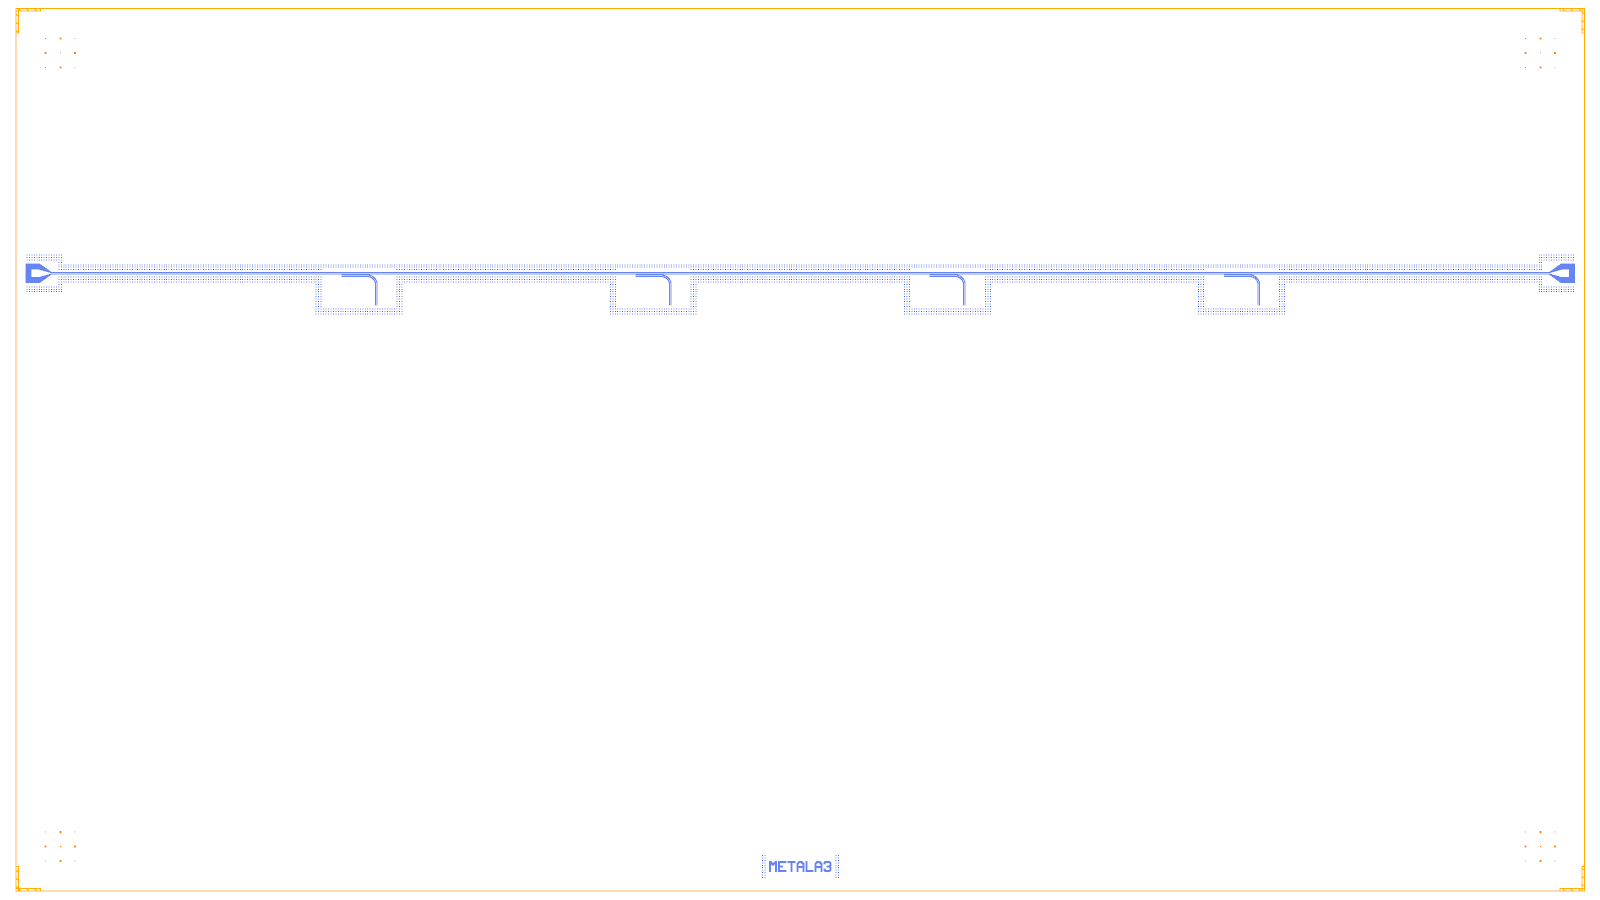

**On the chip so far:** 2 pads · 0 qubits · 4 other components · 5 routes · 0 declared couplings. **This step added** 4 component(s) `clt1`, `clt2`, `clt3`, `clt4` and 5 route(s) `f0`, `f1`, `f2`, `f3`, `f4`.

WindowsPath('examples/designs/metal/a3_four_qubit_mux_s3_readout_line.png')

In [7]:
XS = [-4500, -1500, 1500, 4500]                  # Metal x of the four qubits and their tees (µm)
with d.batch():
    for i, x in enumerate(XS, start=1):
        d.add(f"clt{i}", "metal:CoupledLineTee", at=(X0 + x, Y0 + 1800), coupling_length=350, down_length=300,
              fillet=90, open_termination=False)
    d.route("f0", "LPin.tie", "clt1.prime_start", r=90)
    for i in range(1, 4):
        d.route(f"f{i}", f"clt{i}.prime_end", f"clt{i + 1}.prime_start", r=90)
    d.route("f4", "clt4.prime_end", "LPout.tie", r=90)
print("clt1 ports:", sorted(d["clt1"].ports))
layout_step(d, OUT / "a3_four_qubit_mux_s3_readout_line.png", size=(1600, 900), width=560)

## Design 4 · Qubit placement: four pocket transmons

**The qubits.** Four `metal:TransmonPocket`s with the tutorial's options: two 425 µm pads in a 650 µm-high pocket
and one `readout` connection pad at the upper right. Their junctions are the PDK's: `trilayer_junction` makes the
Quantcore trilayer junction explicit and returns its L_J and C_J for the LOM and the FEM junction port
(`junction=`). The tutorial gives no target frequencies, so all four get the PDK nominal junction (fingers
0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF): the
four qubits stay identical, and only the readouts differ.

Each component has named **ports** (Metal's pins): routes connect to them, and the LOM maps each to a circuit node.
The qubits sit 1.8 mm below the chip centre, each 3.6 mm below its tee. The second picture zooms on the row of qubits
and tees.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['readout', 'squid_a', 'squid_b']


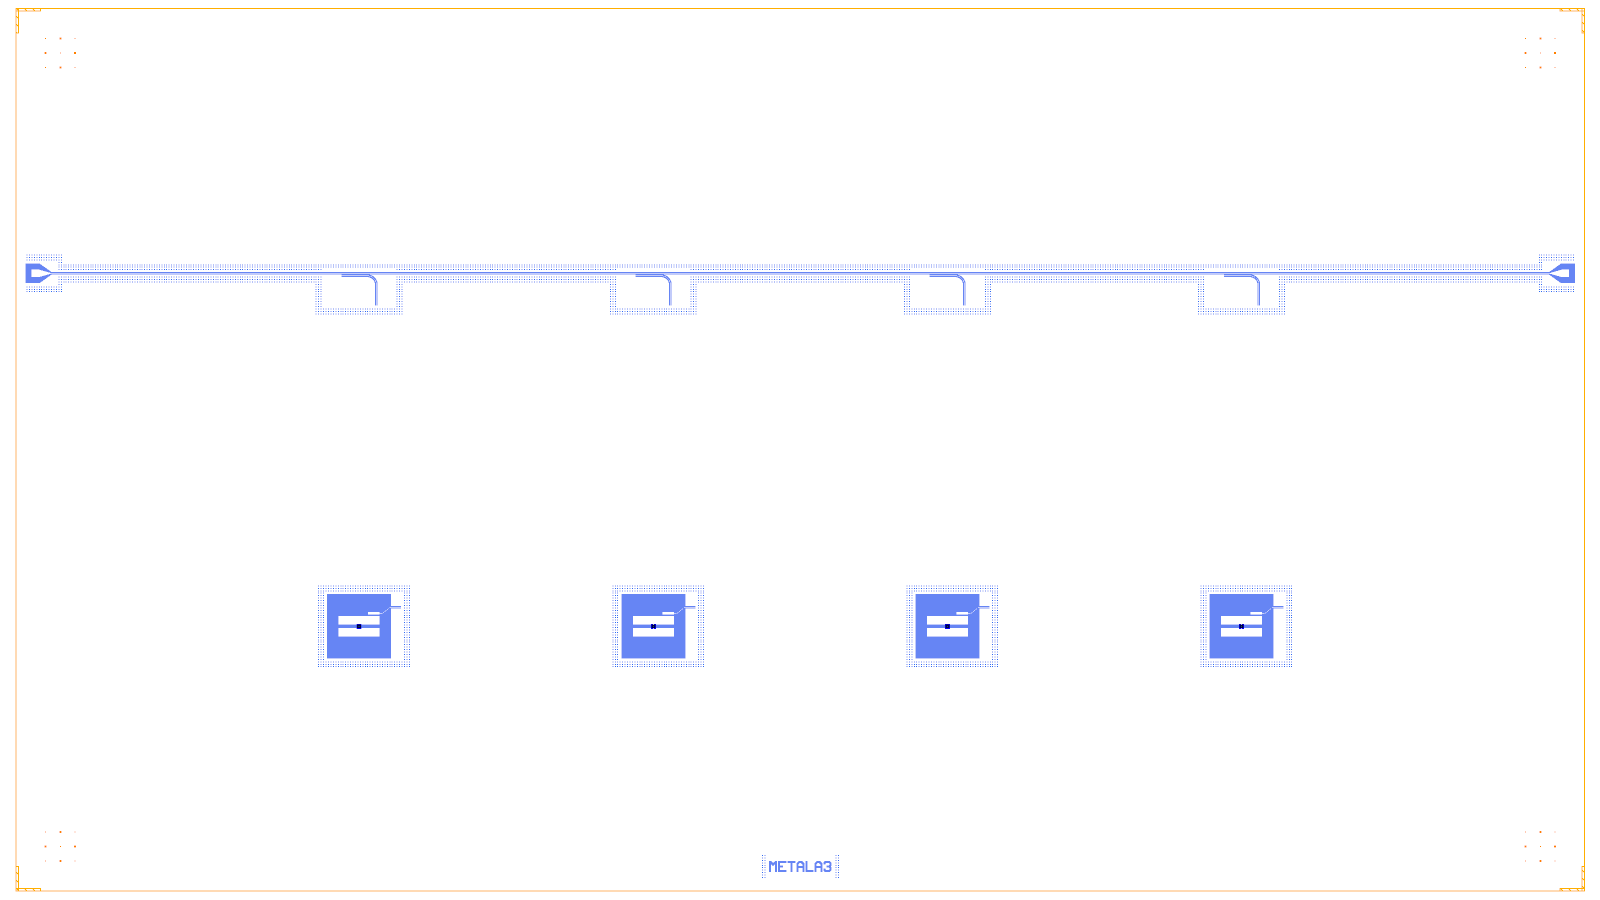

**On the chip so far:** 2 pads · 4 qubits · 4 other components · 5 routes · 0 declared couplings. **This step added** 4 component(s) `Q1`, `Q2`, `Q3`, `Q4`.

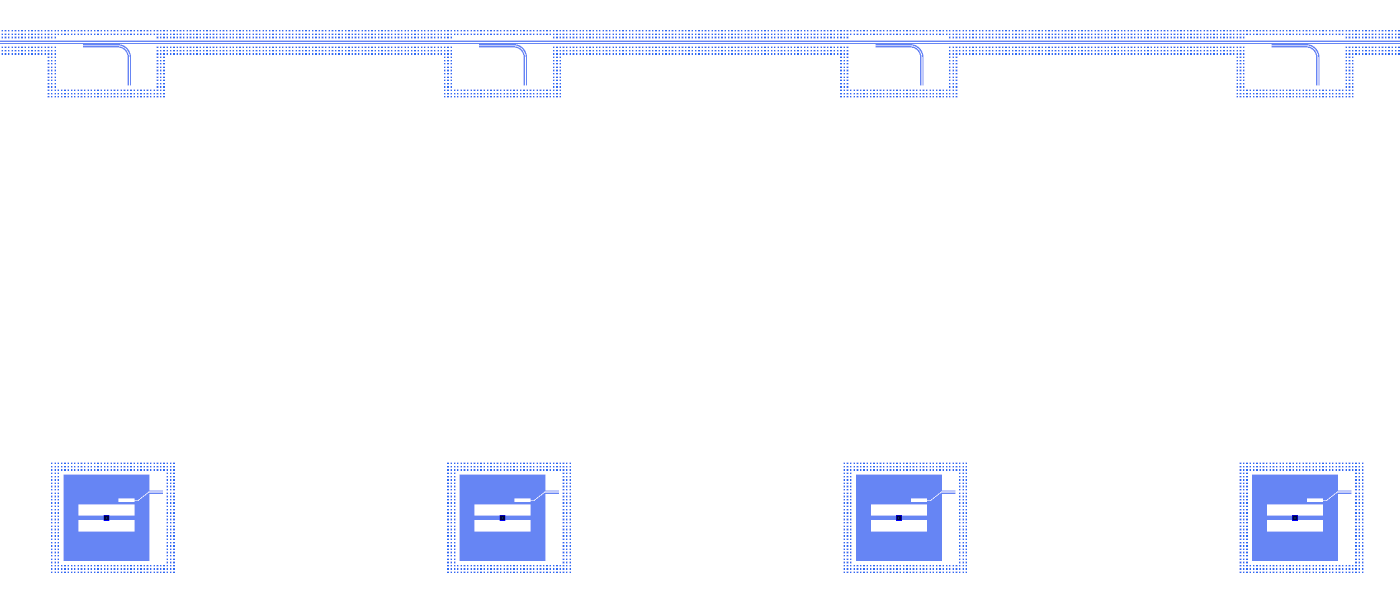

WindowsPath('examples/designs/metal/a3_four_qubit_mux_step_parts.png')

In [8]:
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    for i, x in enumerate(XS, start=1):
        d.add(f"Q{i}", "metal:TransmonPocket", at=(X0 + x, Y0 - 1800), pad_width=425, pocket_height=650,
              connection_pads={"readout": {"loc_W": 1, "loc_H": 1}}, junction=JUNCTION, **JJ_PARAMS)
print("Q1 ports:", sorted(d["Q1"].ports))
layout_step(d, OUT / "a3_four_qubit_mux_s4_qubits.png", size=(1600, 900), width=560)
snap(d, OUT / "a3_four_qubit_mux_step_parts.png", box=(X0 - 5300, Y0 - 2400, X0 + 5300, Y0 + 2100), size=(1400, 600),
     width=560)

## Design 5 · Readout: the four λ/4 readout resonators

Fixed-length routes (6.8, 7.0, 7.2, 7.4 mm) from each tee's coupled arm to its qubit's readout pad; the 200 µm steps
give four tones ≈ 100 MHz apart near 4 GHz (λ/4 on sapphire): one line reads all four. With no waypoints the router
draws the shortest path between the two pins and puts the length it leaves over into one KQC `Meander` on its longest
free straight (turn radius 90 µm, Metal's fillet; Metal's `RouteMeander` has 100 µm lead straights): the same end
points and lengths as the tutorial, a different meander footprint.

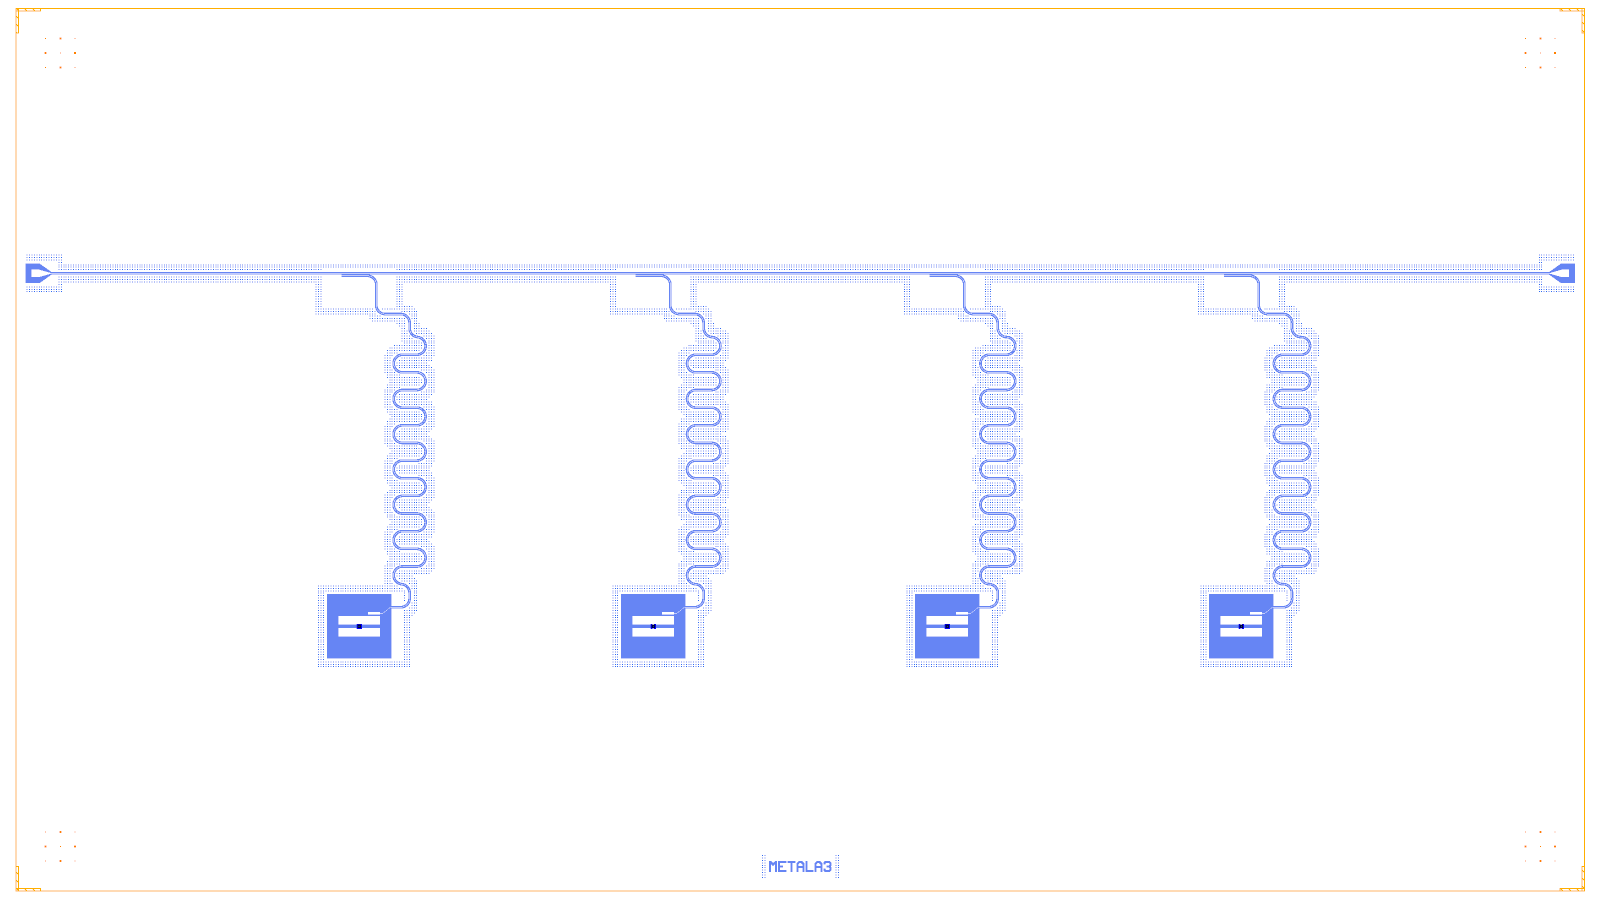

**On the chip so far:** 2 pads · 4 qubits · 4 other components · 9 routes · 0 declared couplings. **This step added** 4 route(s) `read1`, `read2`, `read3`, `read4`.

WindowsPath('examples/designs/metal/a3_four_qubit_mux_s5_readouts.png')

In [9]:
lengths = [6800, 7000, 7200, 7400]
with d.batch():
    for i, length in enumerate(lengths, start=1):
        d.route(f"read{i}", f"clt{i}.second_end", f"Q{i}.readout", meander=length, r=90)
layout_step(d, OUT / "a3_four_qubit_mux_s5_readouts.png", size=(1600, 900), width=560)

## Design 6 · Coupling

The four qubits are deliberately uncoupled (3 mm apart, no bus): each sees only its own readout. Nothing is placed
here.

## Design 7 · Routing: control lines

The tutorial draws no charge or flux lines: the qubits are driven and read through their readouts. Nothing is placed
here.

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups** say what a FEM job cuts out of the chip: each qubit with its readout and tee (`Q<i>_read<i>`), each for
a Q3D C-matrix and an eigenmode job.

**Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). The pads span the die in x, so only y moves (the source's qubits hang below the
feedline).

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*. The
file keeps the previous key order (the tees were added before the qubits here), so `git diff` stays empty.

content shifted by (0.0, 113.5) µm


**Same design as before:** `examples/designs/metal/a3_four_qubit_mux.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer a3_four_qubit_mux: 10 instances, 9 routes, live=False> → examples\designs\metal\a3_four_qubit_mux.json
route lengths (µm): {'f0': 2765.0, 'f1': 2300.0, 'f2': 2300.0, 'f3': 2300.0, 'f4': 2765.0, 'read1': 6800.0, 'read2': 7000.0, 'read3': 7200.0, 'read4': 7400.0}


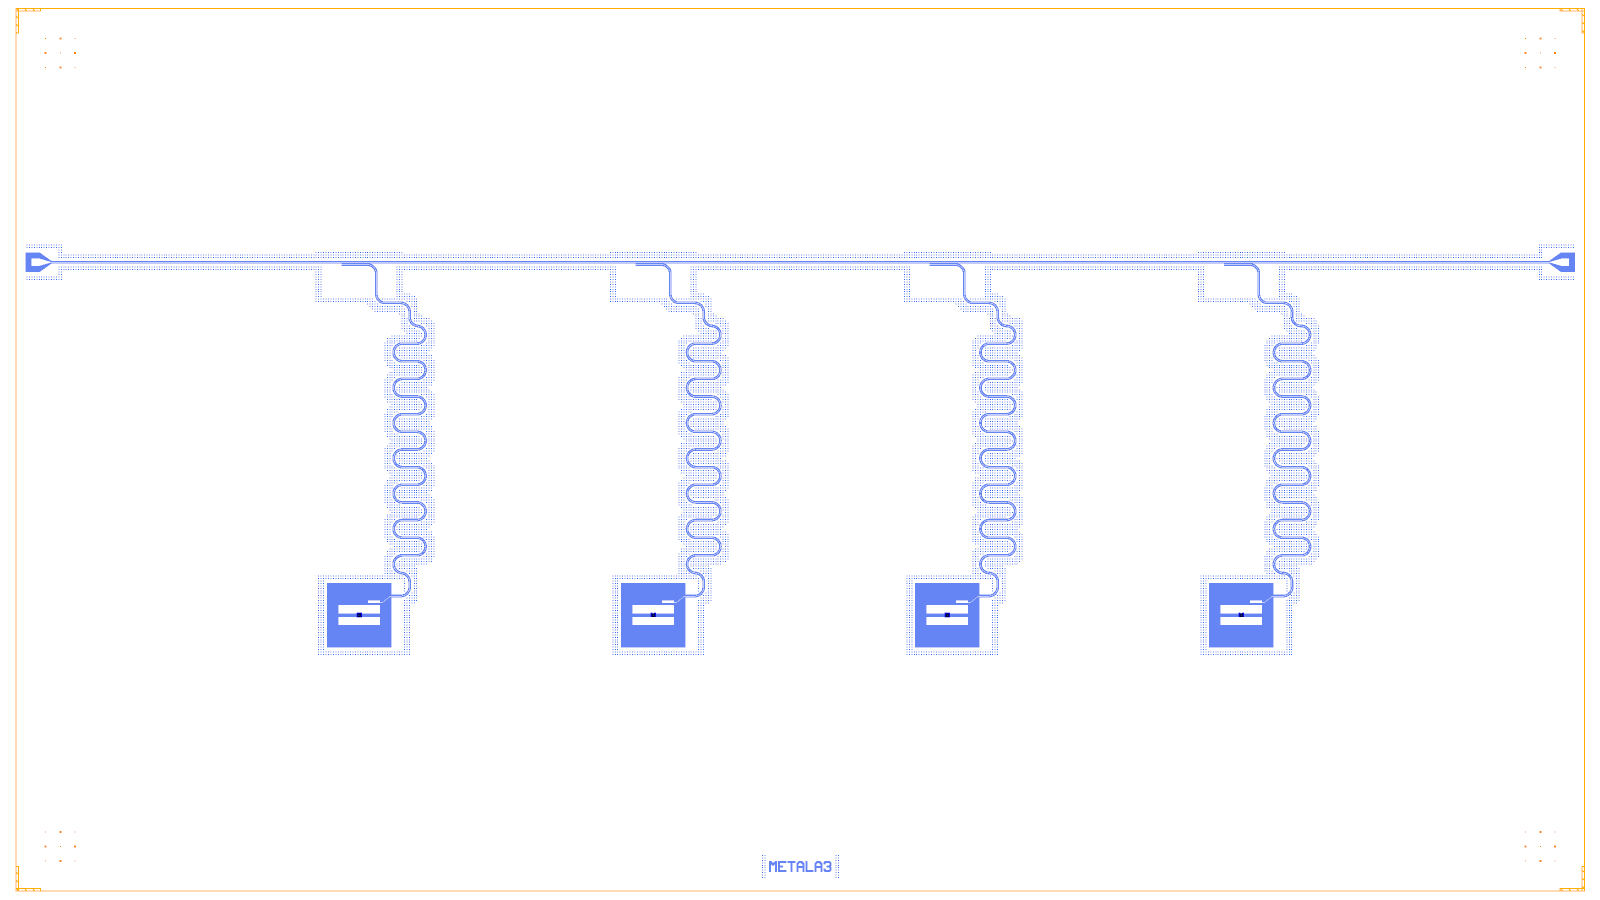

**On the chip so far:** 2 pads · 4 qubits · 4 other components · 9 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a3_four_qubit_mux_step_routes.png')

In [10]:
for i in range(1, 5):
    d.sim_group(f"Q{i}_read{i}", [f"Q{i}", f"read{i}", f"clt{i}"], analyses=["q3d_cmatrix", "eigenmode_epr"])
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN, same = save_design(d, OUT / "a3_four_qubit_mux.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "a3_four_qubit_mux_step_routes.png", size=(1600, 900), width=560)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**, eight `dangling_port` warnings (`squid_a` / `squid_b` of the four qubits, the
junction attachment points: the qubit cell draws the junction itself, nothing is routed there) and **no PDK design
warnings** (the pads are at 100 µm, the nominal junctions are in the R_n window, no target is outside 4–8 GHz).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each `TransmonPocket` is two floating pad nodes with the junction
between them plus a readout-pad node; each readout meander from its shorted tee to the readout pad is a λ/4
`TLres`, the tee's coupled section a hanger κ into the feedline node (two 50 Ω launchpads). The four hangers share
one feedline node: that is the multiplexing. The port map shows which node each port landed on. In the circuit each readout λ/4 is its tee's line
(`clt1`–`clt4`: the coupled arm and the meander together), so the readout values below are `clt<i>.f_GHz`, …

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "clt1."))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Each qubit with its readout and the whole feedline (all four tees, five segments, both launchpads): QuTiP dressed
f_q, α, f_r, κ and χ. With the PDK junction (6.73 nH, 15 fF; numbers from the v1 run) the four identical qubits sit near 7.4 GHz, above the
3.74–4.03 GHz readouts, which step down by ≈ 100 MHz as the meanders grow; the tutorial states no targets.

In [ ]:
feed = ["LPin", "LPout"] + [f"f{i}" for i in range(5)] + [f"clt{i}" for i in range(1, 5)]
results = simulate_groups(d, {f"Q{i}+read{i}": [f"Q{i}", f"read{i}"] + feed for i in range(1, 5)})
display(Markdown(groups_md(results)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each readout. Here (from the
v1 run) the four qubits sit at the same 7.445 GHz while the readouts step down from 4.03 to 3.74 GHz, and |χ| falls
with them (0.24 → 0.16 MHz): the longer readouts are further detuned.

In [ ]:
plot_lom(results, OUT / "a3_four_qubit_mux_lom.png", title="a3: LOM per qubit + readout")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here clt1's coupled length, 350 → 250 µm — rebuild, re-run the LOM of `Q1+read1` and
compare. The coupled length sets how strongly the λ/4 leaks into the feedline: κ falls roughly with its square, the
readout frequency moves a little (the shorter tee arm shortens the λ/4), the qubit barely moves.

In [ ]:
d2 = design_copy(DESIGN)
d2["clt1"].set(coupling_length=250)              # 350 → 250 µm
group = {"Q1+read1": ["Q1", "read1"] + feed}
display(Markdown(params_delta_md({"Q1+read1": results["Q1+read1"]}, simulate_groups(d2, group))))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Per qubit with its readout and tee: a Q3D **C-matrix** job (island pads, readout pad and tee arm) and an
**eigenmode / EPR** job (the lines leaving the box end in 50 Ω, so the mode Q gives κ, and EPR gives the junction
participation): eight jobs.

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each component group `Q<i>_read<i>`: the qubit's two pads, its readout pad, the tee arm and the
feedline the box cuts, as named nets. Each net is named after its LOM node, so the matrix goes straight into the
circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there
are none (four jobs, one after the other).

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same four boxes in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet, the feedline ends the box cuts end
in 50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns
the junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh**
itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim
group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes), the
adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it. Here for `Q1_read1`: its readout is a hanger on the feedline, so S21 between the feedline ports
shows the notch (f_r and the external κ); the other three boxes are the same with longer readouts.

In [ ]:
f_r1 = results["Q1+read1"].params.get("clt1.f_GHz")          # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1_read1", jobs_eig["Q1_read1"][0], keep_eig["Q1_read1"], f_guess=f_r1)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1_read1"]:
    display(Markdown(driven_md(keep_drv["Q1_read1"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {f"{x}{k}": results[f"Q{k}+read{k}"].params.get(f"{x}{k}.{p}")
         for k in (1, 2, 3, 4) for x, p in (("Q", "f_q_GHz"), ("clt", "f_GHz"))}
plot_eigenmodes(keep_eig, OUT / "a3_four_qubit_mux_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch.

In [ ]:
fem_values = {}
for k in (1, 2, 3, 4):
    keep = keep_eig.get(f"Q{k}_read{k}")
    if keep:
        fem_values[f"Q{k}"] = epr_values(keep, {f"Q{k}": f"clt{k}"}, {f"clt{k}": lom_f[f"clt{k}"]})
if keep_drv["Q1_read1"]:
    fem_values.setdefault("Q1", {}).update({f"driven {k}": v for k, v in
                                            driven_values(keep_drv["Q1_read1"], "clt1", f_r1).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for vals in fem_values.values() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α of the four qubits and f_r, χ, κ "
          "of their readouts from pyEPR, and the S21 notch of the Q1 readout.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

read = {f"Q{i}+read{i}": [f"Q{i}", f"read{i}"] + feed for i in range(1, 5)}   # the LOM 1 groups
rows = []
for k in (1, 2, 3, 4):
    g, est = f"Q{k}+read{k}", results[f"Q{k}+read{k}"].params
    keys = [f"Q{k}.f_q_GHz", f"Q{k}.alpha_MHz", f"clt{k}.f_GHz", f"clt{k}.chi_MHz", f"clt{k}.kappa_MHz"]
    if keep_q3d.get(f"Q{k}_read{k}"):
        on_fem = simulate(fill(d.lom(select=read[g]).model, DESIGN, keep_q3d[f"Q{k}_read{k}"]), max_modes=2).params
        rows += [(key, est.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
    for key in keys:
        if key in fem_values.get(f"Q{k}", {}):
            rows.append((key, est.get(key), fem_values[f"Q{k}"][key], "eigenmode + pyEPR"))
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The tutorial states no targets: its four qubits are identical and only the readouts differ. This notebook sets two
targets as an exercise, a frequency plan that spreads the end qubits: **Q1 at 7.2 GHz** and **Q4 at 7.6 GHz**, ≈ 0.25
GHz below and ≈ 0.15 GHz above where the LOM puts all four (from the v1 run: 7.445 GHz). Both are reachable inside
the PDK junction window: by the transmon formula Q1's L_J goes from 6.73 to ≈ 7.2 nH (R_n ≈ 48 kΩ) and Q4's to
≈ 6.5 nH (R_n ≈ 43 kΩ); `pdk_lj_bounds` keeps the feedback within 40–50 kΩ. The readouts are not targeted.

The targets go on a copy (`target_copy` → `build/a3_four_qubit_mux_target.json`), so the design file keeps its own
(none). `loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — on the Q3D values where a solve was kept — and picks one value per quantity (the consensus): four pairs,
so this takes minutes. `loop.feedback` anchors a surrogate on that point and proposes the knobs that put the targets
inside their tolerance (f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision
changes the LOM's L_J; to draw the new junctions, size their fingers with `trilayer_junction(..., lj_nH=...)`.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q1": {"f_q_GHz": 7.2}, "Q4": {"f_q_GHz": 7.6}}   # the exercise targets (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/a3_four_qubit_mux/revisions/`). Without
`RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` the Q3D jobs of the two targeted qubits' groups
are exported and solved first for each revision (`solve_rev`), so the loop closes on FEM values (each solve takes
AEDT minutes). The table shows each iteration's values against the targets and the knobs it moved; the plot the
residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ("Q1_read1", "Q4_read4")}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "a3_four_qubit_mux_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The A.3 tutorial never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip; Q1; its trilayer junction; the clt1 coupled-line tee; the **fab mask** round Q1 (1/0 etch with the
PDK cheese band, the 3/0 keep-out, the junction layers); and the die frame's south-west corner (dicing L on 1000/0,
alignment grid on 1001/0). Positions are read from the design (after the centring shift).

In [ ]:
QX, QY = d.data["instances"]["Q1"]["place"]["at"]
TX, TY = d.data["instances"]["clt1"]["place"]["at"]
show_snapshot(d, OUT / "a3_four_qubit_mux.png", size=(1800, 1100))
show_snapshot(d, OUT / "a3_four_qubit_mux_q1.png", box=(QX - 450, QY - 450, QX + 450, QY + 450), width=420)
show_snapshot(d, OUT / "a3_four_qubit_mux_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
show_snapshot(d, OUT / "a3_four_qubit_mux_tee.png", box=(TX - 300, TY - 400, TX + 300, TY + 200), width=360)
snap_file(Path("build") / "a3_four_qubit_mux_fab.oas", OUT / "a3_four_qubit_mux_cheese.png",
          box=(QX - 650, QY - 650, QX + 650, QY + 650), size=(1300, 1300), width=420)
show_snapshot(d, OUT / "a3_four_qubit_mux_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, the five feedline segments, the route end pins, the readout lengths (6.8 / 7.0 / 7.2 / 7.4 mm), the sim groups |
| PDK changes | QCT frame on the source's 16 × 9 mm box; sapphire stack; launchpads 100 µm from the west / east edges (were 240 µm); trilayer junctions (PDK nominal); PDK cheese band; content centred (shift printed in Design 8) |
| differs | the meanders' shapes (qcc router); f_q ≈ 7.4 GHz with the PDK junction (from the v1 run; the 10 nH Metal default gave 6.75 GHz) |
| PDK design warnings | none |
| layout | built in segments (die, pads, the tees on the feedline, the qubits, the readouts, the whole chip); the saved JSON is the v1 notebook's |
| feedback | exercise targets on a copy (Q1 7.2 GHz, Q4 7.6 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |